In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipaddress

from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)

In [2]:
FILE_PATH = "SolarWinds_History_10-30_September_2026 - Copy (1).xlsx"

OUTPUT_FILE = "SolarWinds_September_Trend_Analysis.xlsx"

In [3]:
daily = pd.read_excel(
    FILE_PATH,
    sheet_name="Daily summary",
    header=6
)

availability = pd.read_excel(
    FILE_PATH,
    sheet_name="Availability history",
    header=5
)

resources = pd.read_excel(
    FILE_PATH,
    sheet_name="CPU and memory history",
    header=5
)

nodes = pd.read_excel(
    FILE_PATH,
    sheet_name="Current node names",
    header=5
)

print("Daily summary shape:", daily.shape)
print("Availability history shape:", availability.shape)
print("CPU and memory history shape:", resources.shape)
print("Current node names shape:", nodes.shape)

Daily summary shape: (39, 10)
Availability history shape: (31688, 16)
CPU and memory history shape: (16808, 14)
Current node names shape: (1620, 5)


In [4]:
daily["Source date"] = pd.to_datetime(
    daily["Source date"],
    errors="coerce"
).dt.normalize()

daily = daily.dropna(subset=["Source date"]).copy()

for frame in [availability, resources]:
    frame["Source date"] = pd.to_datetime(
        frame["Source date"],
        errors="coerce"
    ).dt.normalize()

    frame.dropna(
        subset=["Source date", "Node ID"],
        inplace=True
    )

print("Analysis period:")
print(daily["Source date"].min(), "to", daily["Source date"].max())

print("Number of daily summary dates:", daily["Source date"].nunique())
print("Availability records:", len(availability))
print("Resource records:", len(resources))

Analysis period:
2026-09-10 00:00:00 to 2026-09-30 00:00:00
Number of daily summary dates: 21
Availability records: 31688
Resource records: 16808


Converting metric columns to Numeric

In [5]:
daily_numeric_columns = [
    "Mean availability",
    "Mean response (ms)",
    "Mean packet loss",
    "Mean CPU",
    "Mean memory",
    "Availability nodes",
    "CPU/memory nodes",
    "Availability records",
    "Resource records"
]

availability_numeric_columns = [
    "Mean availability",
    "Peak availability",
    "Mean response (ms)",
    "Peak response (ms)",
    "Mean packet loss",
    "Peak packet loss"
]

resource_numeric_columns = [
    "Mean CPU",
    "Peak CPU",
    "Mean memory",
    "Peak memory"
]

for col in daily_numeric_columns:
    if col in daily.columns:
        daily[col] = pd.to_numeric(daily[col], errors="coerce")

for col in availability_numeric_columns:
    if col in availability.columns:
        availability[col] = pd.to_numeric(
            availability[col], errors="coerce"
        )

for col in resource_numeric_columns:
    if col in resources.columns:
        resources[col] = pd.to_numeric(
            resources[col], errors="coerce"
        )

print("Numeric conversion completed.")

Numeric conversion completed.


In [6]:
print("Duplicate daily summary dates:",
      daily["Source date"].duplicated().sum())

print("Duplicate date + Node ID rows in availability:",
      availability.duplicated(["Source date", "Node ID"]).sum())

print("Duplicate date + Node ID rows in resources:",
      resources.duplicated(["Source date", "Node ID"]).sum())

print("Unique availability Node IDs:",
      availability["Node ID"].nunique())

print("Unique resource Node IDs:",
      resources["Node ID"].nunique())

print("Missing availability values:")
display(availability.isna().sum().sort_values(ascending=False))

print("Missing resource values:")
display(resources.isna().sum().sort_values(ascending=False))

Duplicate daily summary dates: 0
Duplicate date + Node ID rows in availability: 0
Duplicate date + Node ID rows in resources: 0
Unique availability Node IDs: 1685
Unique resource Node IDs: 853
Missing availability values:


Mean response (ms)               349
Peak response (ms)               349
Source date                        0
Node ID                            0
Current node name                  0
Source records                     0
First source timestamp             0
Last source timestamp              0
Availability valid records         0
Availability sum (pct points)      0
Mean availability                  0
Response valid records             0
Response sum (ms)                  0
Loss valid records                 0
Loss sum (pct points)              0
Mean packet loss                   0
dtype: int64

Missing resource values:


Source date                0
Node ID                    0
Current node name          0
Source records             0
First source timestamp     0
Last source timestamp      0
CPU valid records          0
CPU sum (pct points)       0
Mean CPU                   0
Peak CPU                   0
Memory valid records       0
Memory sum (pct points)    0
Mean memory                0
Peak memory                0
dtype: int64

# Daily Trend Analysis

Daily Trend Metrics

In [7]:
daily_trend = daily[
    [
        "Source date",
        "Mean availability",
        "Mean response (ms)",
        "Mean packet loss",
        "Mean CPU",
        "Mean memory"
    ]
].copy()

daily_trend["Availability_pct"] = (
    daily_trend["Mean availability"] * 100
)

daily_trend["Packet_loss_pct"] = (
    daily_trend["Mean packet loss"] * 100
)

daily_trend["CPU_pct"] = (
    daily_trend["Mean CPU"] * 100
)

daily_trend["Memory_pct"] = (
    daily_trend["Mean memory"] * 100
)

daily_trend = daily_trend.sort_values("Source date")

display(daily_trend.round(3))

,Source date,Mean availability,Mean response (ms),Mean packet loss,Mean CPU,Mean memory,Availability_pct,Packet_loss_pct,CPU_pct,Memory_pct
0,2026-09-10,0.983,43.367,0.025,0.155,0.393,98.304,2.479,15.493,39.266
1,2026-09-11,0.982,44.593,0.019,0.146,0.394,98.223,1.949,14.607,39.383
2,2026-09-12,0.981,47.531,0.022,0.138,0.395,98.061,2.160,13.804,39.530
3,2026-09-13,0.979,48.853,0.023,0.138,0.396,97.918,2.272,13.766,39.554
4,2026-09-14,0.976,47.933,0.027,0.147,0.397,97.552,2.655,14.695,39.687
5,2026-09-15,0.976,47.277,0.027,0.148,0.396,97.577,2.659,14.828,39.591
6,2026-09-16,0.991,41.307,0.012,0.145,0.389,99.087,1.246,14.491,38.888
7,2026-09-17,0.989,41.205,0.019,0.151,0.388,98.858,1.866,15.064,38.840
8,2026-09-18,0.980,42.344,0.024,0.148,0.391,97.984,2.379,14.756,39.080
9,2026-09-19,0.967,42.712,0.037,0.136,0.395,96.652,3.673,13.636,39.513


Mean Availability Plot

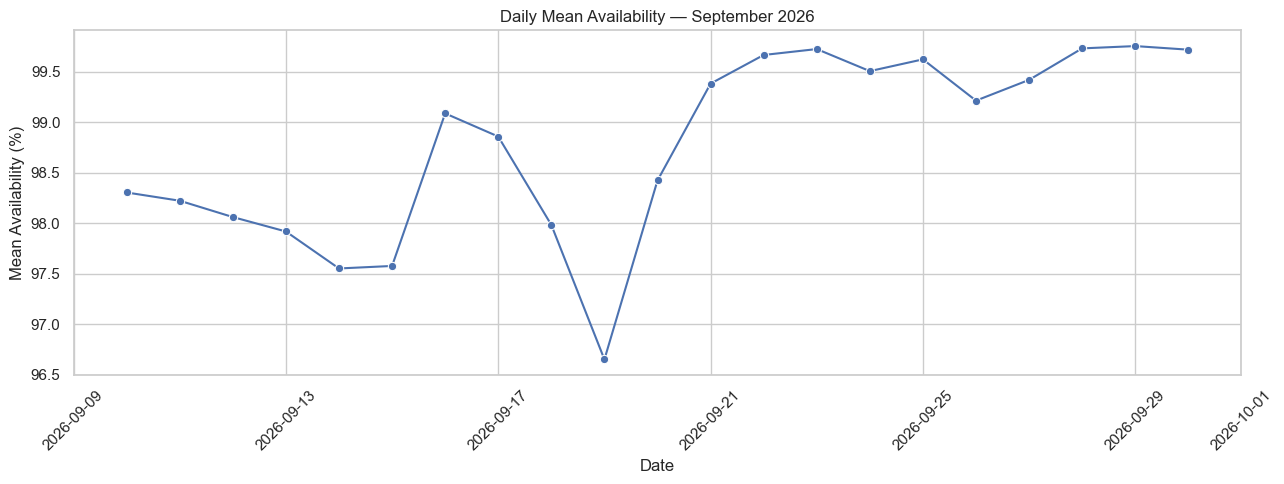

In [8]:
plt.figure(figsize=(13, 5))

sns.lineplot(
    data=daily_trend,
    x="Source date",
    y="Availability_pct",
    marker="o"
)

plt.title("Daily Mean Availability — September 2026")
plt.xlabel("Date")
plt.ylabel("Mean Availability (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Plot daily mean response time

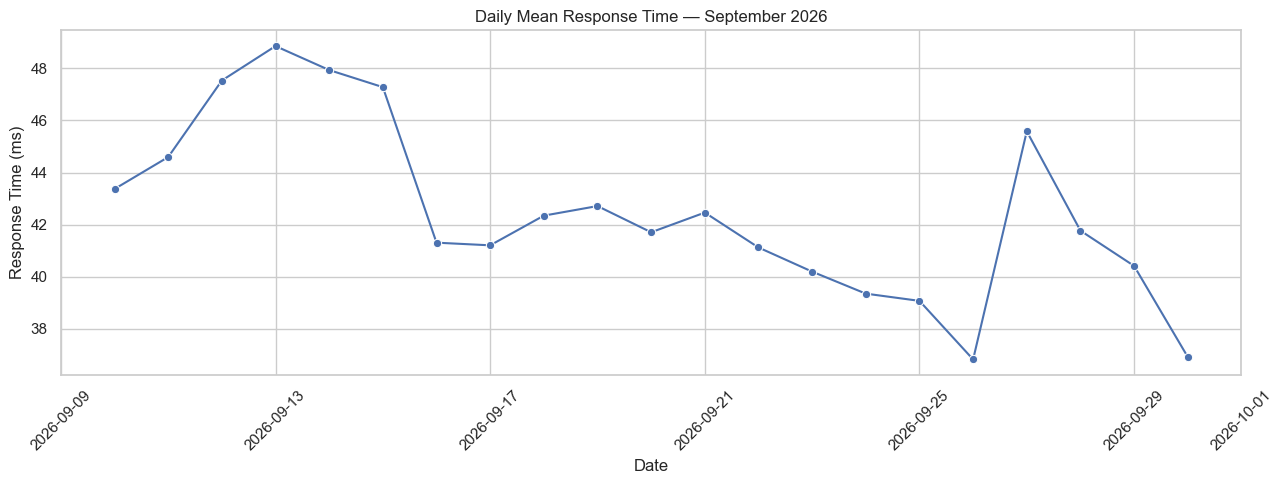

In [9]:
plt.figure(figsize=(13, 5))

sns.lineplot(
    data=daily_trend,
    x="Source date",
    y="Mean response (ms)",
    marker="o"
)

plt.title("Daily Mean Response Time — September 2026")
plt.xlabel("Date")
plt.ylabel("Response Time (ms)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Plot CPU & Memory Trends

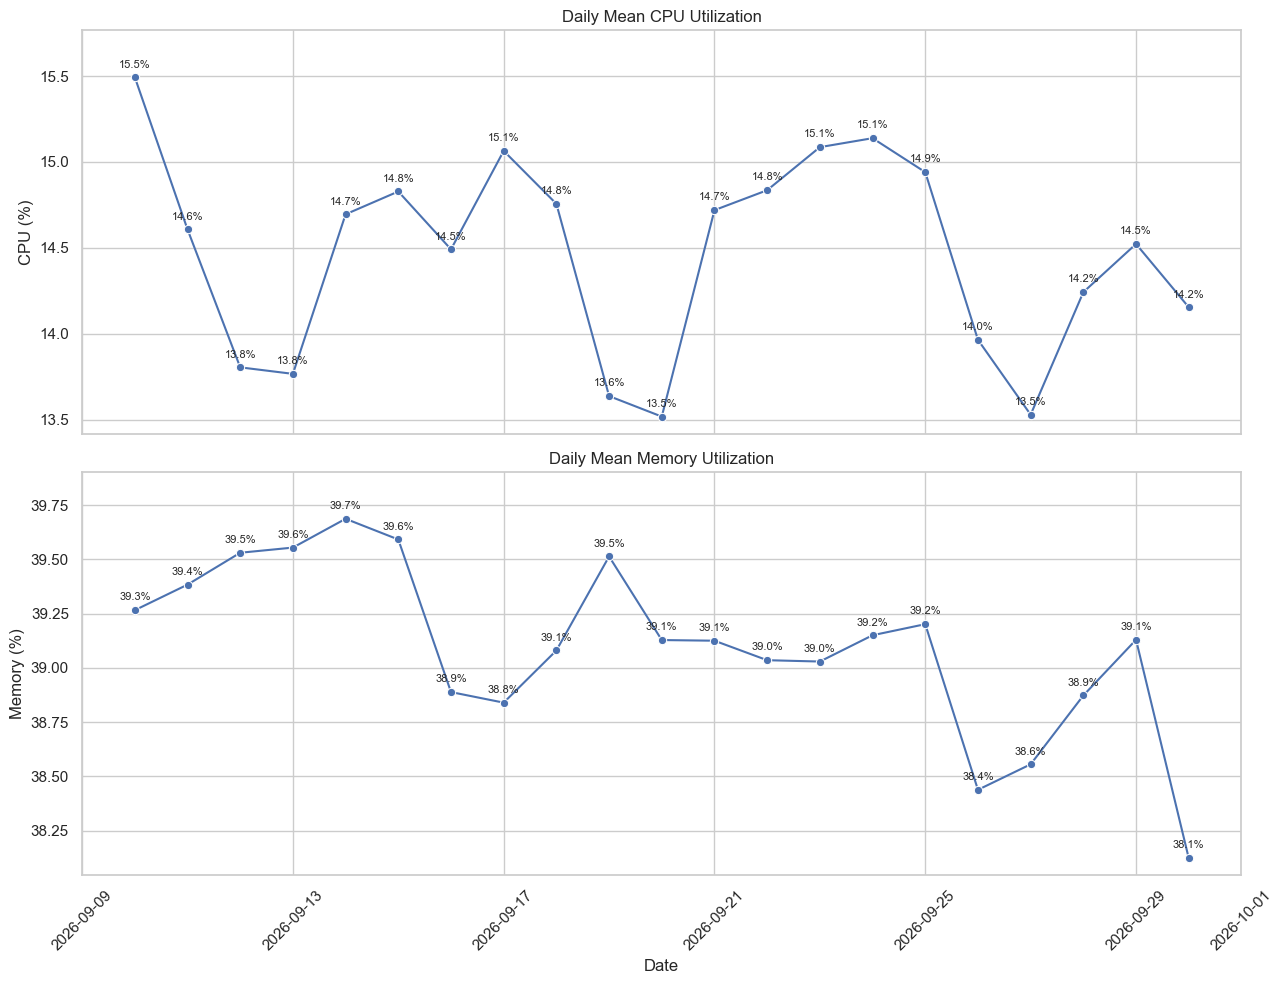

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(13, 10), sharex=True)

# 1. CPU Utilization Subplot
sns.lineplot(
    data=daily_trend,
    x="Source date",
    y="CPU_pct",
    marker="o",
    ax=axes[0]
)
axes[0].set_title("Daily Mean CPU Utilization")
axes[0].set_ylabel("CPU (%)")

# Annotate values on each point for CPU
for _, row in daily_trend.dropna(subset=["Source date", "CPU_pct"]).iterrows():
    axes[0].annotate(
        f"{row['CPU_pct']:.1f}%",
        (row["Source date"], row["CPU_pct"]),
        textcoords="offset points",
        xytext=(0, 7),
        ha="center",
        fontsize=8
    )

# 2. Memory Utilization Subplot
sns.lineplot(
    data=daily_trend,
    x="Source date",
    y="Memory_pct",
    marker="o",
    ax=axes[1]
)
axes[1].set_title("Daily Mean Memory Utilization")
axes[1].set_ylabel("Memory (%)")
axes[1].set_xlabel("Date")

# Annotate values on each point for Memory
for _, row in daily_trend.dropna(subset=["Source date", "Memory_pct"]).iterrows():
    axes[1].annotate(
        f"{row['Memory_pct']:.1f}%",
        (row["Source date"], row["Memory_pct"]),
        textcoords="offset points",
        xytext=(0, 7),
        ha="center",
        fontsize=8
    )

# Expand y-limits slightly so top labels don't get clipped
for ax in axes:
    ymin, ymax = ax.get_ylim()
    ax.set_ylim(ymin, ymax + (ymax - ymin) * 0.08)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Comparison Between 10th and 30th September 2026

In [13]:
daily_sorted = daily_trend.sort_values("Source date")

first_day = daily_sorted.iloc[0]
last_day = daily_sorted.iloc[-1]

comparison_metrics = {
    "Availability (%)": "Availability_pct",
    "Response time (ms)": "Mean response (ms)",
    "Packet loss (%)": "Packet_loss_pct",
    "CPU utilization (%)": "CPU_pct",
    "Memory utilization (%)": "Memory_pct"
}

comparison_rows = []

for metric_name, column in comparison_metrics.items():
    first_value = first_day[column]
    last_value = last_day[column]

    comparison_rows.append({
        "Metric": metric_name,
        "10 September": first_value,
        "30 September": last_value,
        "Absolute Change": last_value - first_value,
        "Relative Change (%)": (
            (last_value - first_value) / abs(first_value) * 100
            if pd.notna(first_value) and first_value != 0
            else np.nan
        )
    })

endpoint_comparison = pd.DataFrame(comparison_rows)

display(endpoint_comparison.round(3))

,Metric,10 September,30 September,Absolute Change,Relative Change (%)
0,Availability (%),98.304,99.718,1.413,1.438
1,Response time (ms),43.367,36.919,-6.449,-14.870
2,Packet loss (%),2.479,0.554,-1.925,-77.660
3,CPU utilization (%),15.493,14.154,-1.339,-8.644
4,Memory utilization (%),39.266,38.124,-1.142,-2.908
